In [50]:
import pandas as pd
import seaborn as sb
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA


In [51]:
rfm = pd.read_csv("../data/rfm.csv")

In [52]:
rfm_log = rfm.copy()

rfm_log["Recency"] = np.log1p(rfm_log["Recency"])
rfm_log["Frequency"] = np.log1p(rfm_log["Frequency"])
rfm_log["Monetary"] = np.log1p(rfm_log["Monetary"])

In [53]:
features = ["Recency", "Frequency", "Monetary"]

X_rfm = rfm_log[features]

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_rfm)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=features,
    index=rfm.index
)

X_scaled.head()

,Recency,Frequency,Monetary
0,1.461993,-0.955214,3.706225
1,-2.038734,1.074425,1.411843
2,0.373104,0.386304,0.716489
3,-0.623086,-0.955214,0.698739
4,1.424558,-0.955214,-0.618962


In [54]:
X_scaled.describe().T

,count,mean,std,min,25%,50%,75%,max
Recency,4338.0,-8.025955e-17,1.000115,-2.341296,-0.661361,0.089926,0.844792,1.564198
Frequency,4338.0,-8.189750e-18,1.000115,-0.955214,-0.955214,-0.361583,0.653237,5.858535
Monetary,4338.0,3.079346e-16,1.000115,-4.004574,-0.685668,-0.062187,0.654186,4.731591


In [55]:
k_values = range(2, 10)

inertias = []
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels = kmeans.fit_predict(X_scaled)
    
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(
        silhouette_score(X_scaled, labels,random_state=42)
    )


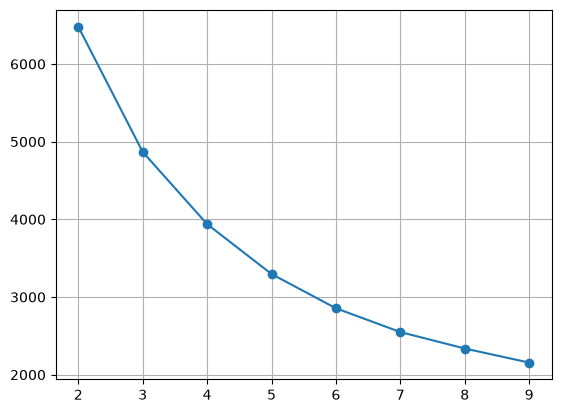

In [56]:
plt.plot(k_values,inertias,marker="o")
plt.grid()

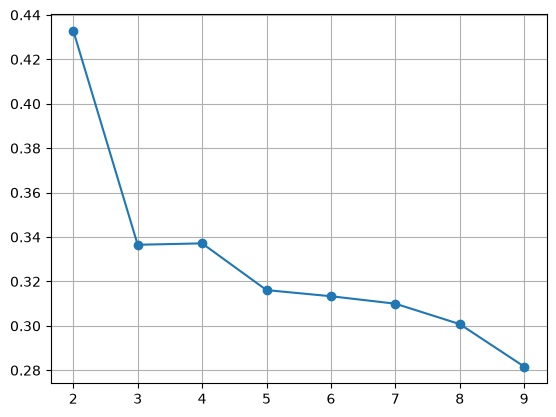

In [57]:
plt.plot(k_values,silhouette_scores,marker="o")
plt.grid()

In [58]:
kmeans = KMeans(n_clusters=3,random_state=42)
rfm["Cluster"]=kmeans.fit_predict(X_scaled)

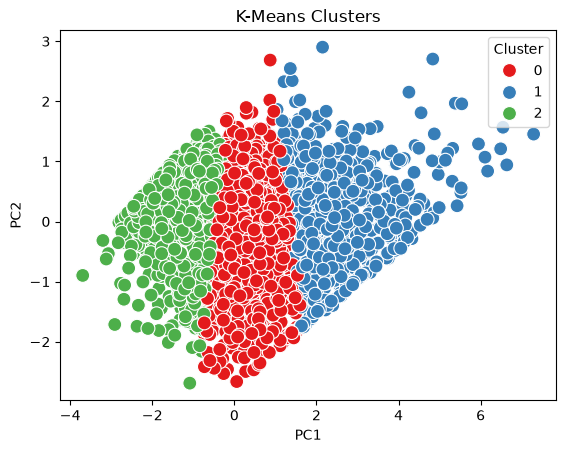

In [59]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

rfm['PC1'] = X_pca[:, 0]
rfm['PC2'] = X_pca[:, 1]
sb.scatterplot(
    data=rfm,
    x='PC1',
    y='PC2',
    hue='Cluster',
    palette='Set1',
    s=100
)

plt.title('K-Means Clusters')
plt.show()

In [60]:
rfm.groupby("Cluster").describe()

CustomerID                                                         \
             count          mean          std      min       25%      50%   
Cluster                                                                     
0           1696.0  15272.406840  1711.604745  12346.0  13771.75  15288.5   
1            776.0  15205.404639  1767.523310  12347.0  13703.00  15119.5   
2           1866.0  15365.366559  1710.165952  12350.0  13890.00  15360.5   

                          Recency              ...       PC1            \
             75%      max   count        mean  ...       75%       max   
Cluster                                        ...                       
0        16728.5  18287.0  1696.0   44.463443  ...  0.796886  1.605546   
1        16784.0  18283.0   776.0   17.070876  ...  2.869896  7.290288   
2        16811.5  18281.0  1866.0  167.613076  ... -0.903881 -0.270390   

            PC2                                                              \
          count      mean       std       min       25%       50%       75%   
Cluster                                                                       
0        1696.0 -0.157673  0.821851 -2.662867 -0.682767 -0.091543  0.439136   
1         776.0  0.113428  0.771213 -1.753753 -0.408699  0.102746  0.645493   
2        1866.0  0.096138  0.640925 -2.689450 -0.301956  0.214168  0.564956   

                   
              max  
Cluster            
0        2.686758  
1        2.901902  
2        1.505521  

[3 rows x 48 columns]

In [61]:
labels = {
    0: "Loyal",
    1: "Casual",
    2: "High"
}
rfm["Cluster"] = rfm["Cluster"].map(labels)
rfm.head()

,CustomerID,Recency,Frequency,Monetary,Cluster,PC1,PC2
0,12346.0,326,1,77183.60,Loyal,0.872658,2.686758
1,12347.0,2,7,4310.00,Casual,2.550260,-0.804427
2,12348.0,75,4,1797.24,Loyal,0.475142,0.746121
3,12349.0,19,1,1757.55,Loyal,0.145832,-0.460480
4,12350.0,310,1,334.40,High,-1.688990,0.676555


In [62]:
centers = kmeans.cluster_centers_
np.expm1(scaler.inverse_transform(centers))

array([[2.87299102e+01, 3.09177681e+00, 9.52899969e+02],
       [9.21602817e+00, 1.06116091e+01, 4.24063687e+03],
       [1.28104287e+02, 1.28111791e+00, 2.73314944e+02]])

In [65]:
rfm[["CustomerID","Recency","Frequency","Monetary","Cluster"]].to_csv("../data/clients_rfm.csv")